In [2]:
%pip install -r requirements.txt

You should consider upgrading via the '/Users/ivanb/VisualStudio/saa-caso5sonrievlc/.venv/bin/python -m pip install --upgrade pip' command.
Note: you may need to restart the kernel to use updated packages.


In [3]:
import sys
print(sys.executable)

/Users/ivanb/VisualStudio/saa-caso5sonrievlc/.venv/bin/python


In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import statistics as st

In [5]:
# Cargar dataset
df = pd.read_csv("sonrievalencia_citas.csv", sep=";")

In [6]:
print(f"Registros: {df.shape[0]}")
print(f"Columnas: {df.shape[1]}")

Registros: 2400
Columnas: 19


Grafico de numero de clientes por clinica

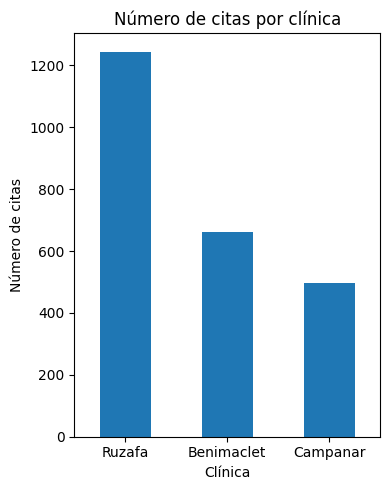

In [7]:
df['clinica'].value_counts().plot(
    kind='bar',
    figsize=(4, 5)
)

plt.title('Número de citas por clínica')
plt.xlabel('Clínica')
plt.ylabel('Número de citas')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

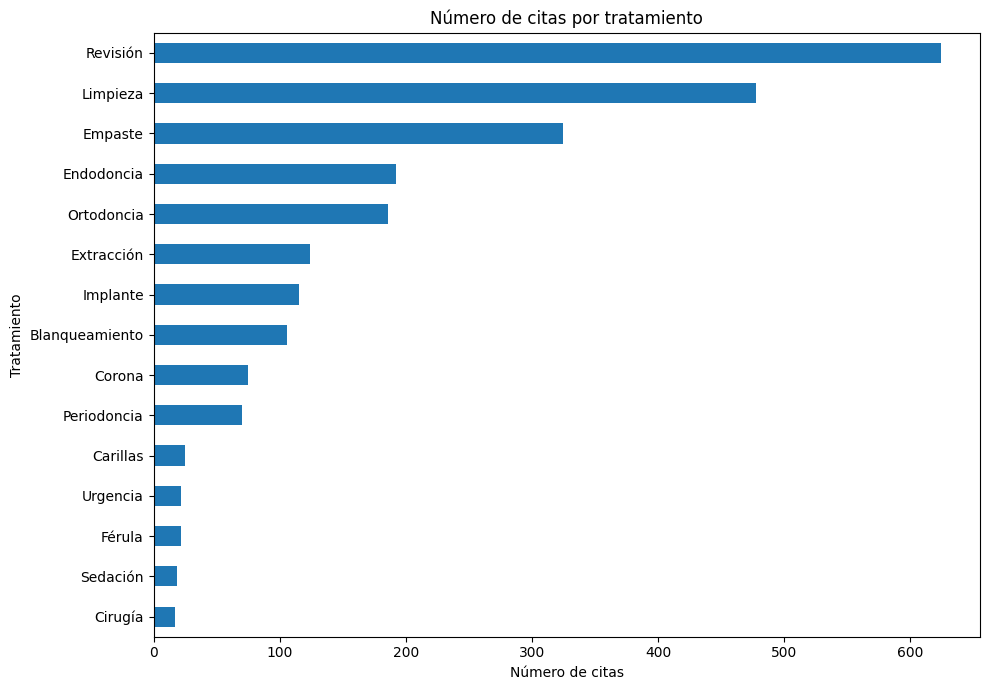

In [8]:
df['tratamiento'].value_counts().sort_values().plot(
    kind='barh',
    figsize=(10, 7)
)

plt.title('Número de citas por tratamiento')
plt.xlabel('Número de citas')
plt.ylabel('Tratamiento')
plt.tight_layout()
plt.show()

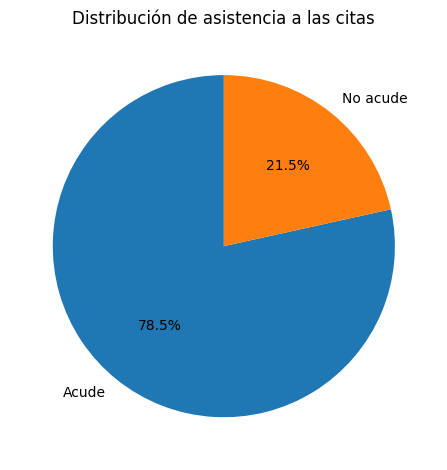

In [9]:
ausencias = df['no_acude'].value_counts()

ausencias.plot(
    kind='pie',
    autopct='%1.1f%%',
    startangle=90,
    labels=['Acude', 'No acude']
)

plt.title('Distribución de asistencia a las citas')
plt.ylabel('')
plt.tight_layout()
plt.show()

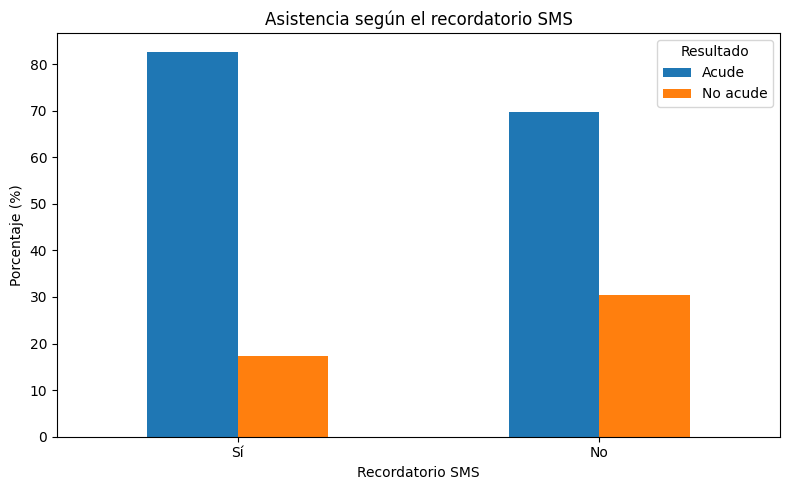

In [10]:
datos_sms = df[
    df['recordatorio_sms'].isin(['Sí', 'No'])
].copy()

tabla_sms = pd.crosstab(
    datos_sms['recordatorio_sms'],
    datos_sms['no_acude'],
    normalize='index'
) * 100

tabla_sms = tabla_sms.reindex(
    index=['Sí', 'No'],
    columns=['No', 'Sí']
)

tabla_sms.plot(
    kind='bar',
    figsize=(8, 5)
)

plt.title('Asistencia según el recordatorio SMS')
plt.xlabel('Recordatorio SMS')
plt.ylabel('Porcentaje (%)')
plt.xticks(rotation=0)
plt.legend(['Acude', 'No acude'], title='Resultado')
plt.tight_layout()
plt.show()

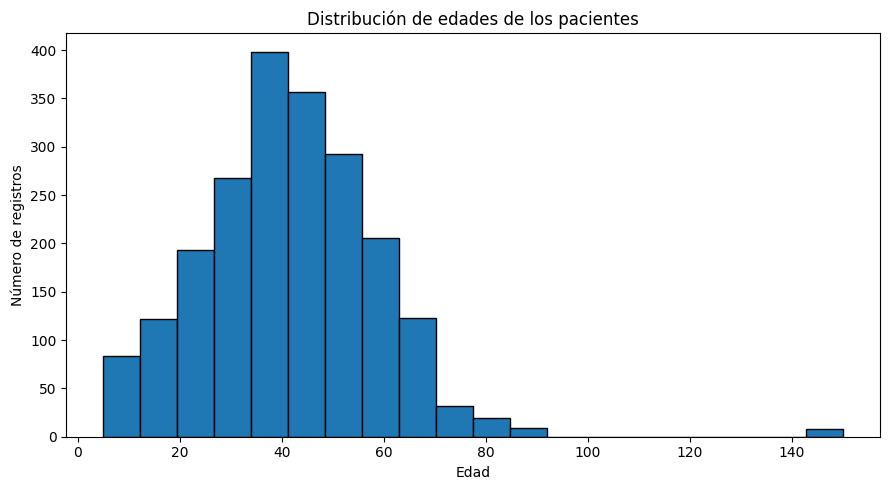

In [11]:
edades = df['edad'].dropna()

plt.figure(figsize=(9, 5))
plt.hist(edades, bins=20, edgecolor='black')

plt.title('Distribución de edades de los pacientes')
plt.xlabel('Edad')
plt.ylabel('Número de registros')
plt.tight_layout()
plt.show()

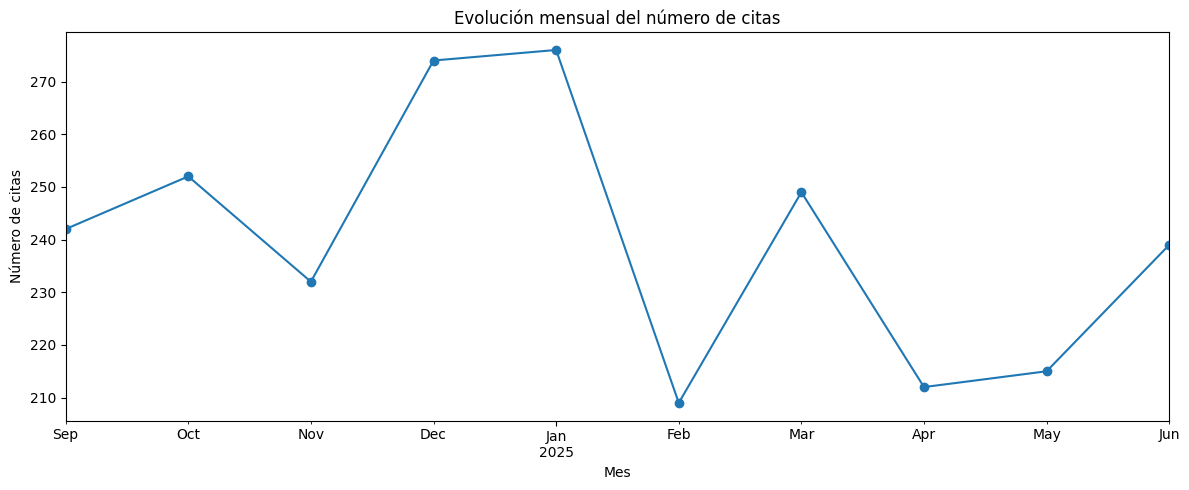

In [12]:
df['fecha_cita'] = pd.to_datetime(
    df['fecha_cita'],
    errors='coerce'
)

citas_mensuales = (
    df.dropna(subset=['fecha_cita'])
      .set_index('fecha_cita')
      .resample('MS')
      .size()
)

plt.figure(figsize=(12, 5))
citas_mensuales.plot(marker='o')

plt.title('Evolución mensual del número de citas')
plt.xlabel('Mes')
plt.ylabel('Número de citas')
plt.tight_layout()
plt.show()

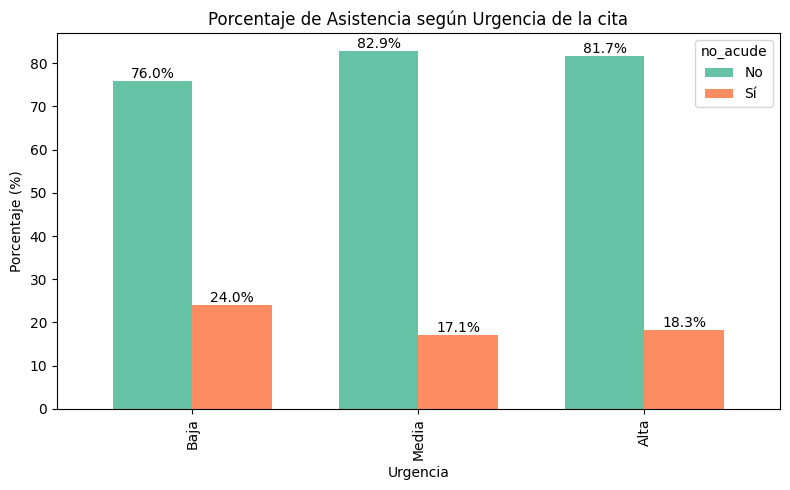

In [59]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# 1. Calculamos los porcentajes (normalize='index' calcula la proporción dentro de cada grupo)
df_porcentajes = pd.crosstab(df['urgencia'], df['no_acude'], normalize='index') * 100
df_porcentajes = df_porcentajes.loc[['Baja', 'Media', 'Alta']]
# 2. Creamos el gráfico de barras
ax = df_porcentajes.plot(kind='bar', figsize=(8, 5), color=sns.color_palette('Set2'), width=0.7)


plt.title('Porcentaje de Asistencia según Urgencia de la cita')
plt.ylabel('Porcentaje (%)')
plt.xlabel('Urgencia')
plt.legend(title='no_acude')

for p in ax.patches:
    ax.annotate(f'{p.get_height():.1f}%', 
                (p.get_x() + p.get_width() / 2., p.get_height()), 
                ha='center', va='bottom')

plt.tight_layout()
plt.show()

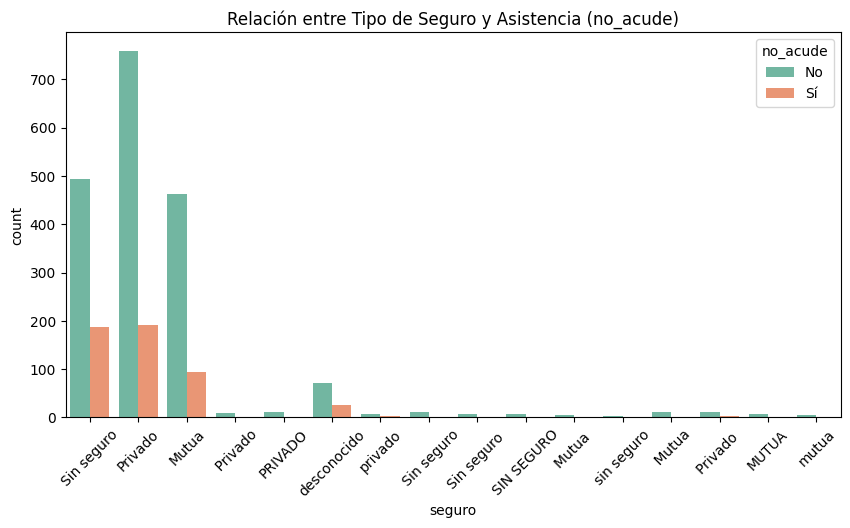

In [26]:
plt.figure(figsize=(10, 5))
sns.countplot(data=df, x='seguro', hue='no_acude', palette='Set2')
plt.title('Relación entre Tipo de Seguro y Asistencia (no_acude)')
plt.xticks(rotation=45) # Rotamos las etiquetas por si hay muchos seguros
plt.show()

Los datos mostrados en la parte superior estan muy manchados debido a la falta de normalizacion asi que hay que tratar los datos

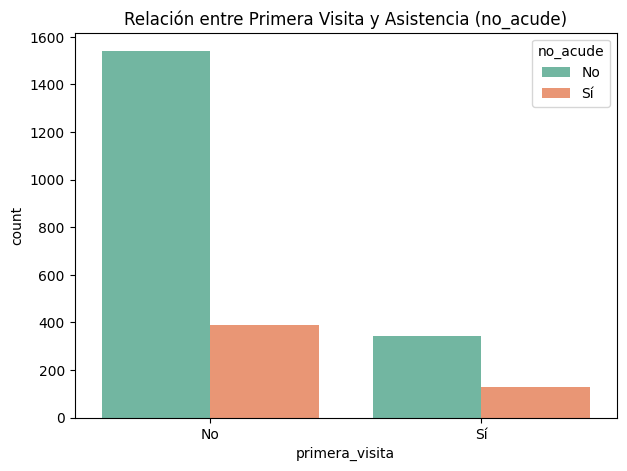

In [27]:
plt.figure(figsize=(7, 5))
sns.countplot(data=df, x='primera_visita', hue='no_acude', palette='Set2')
plt.title('Relación entre Primera Visita y Asistencia (no_acude)')
plt.show()

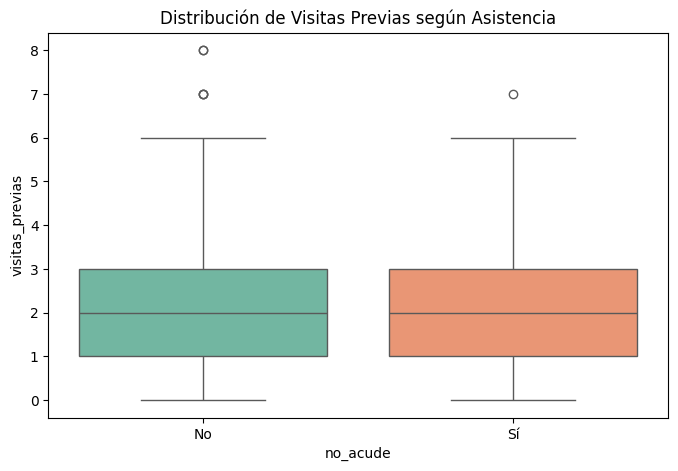

In [ ]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x='no_acude', y='visitas_previas', palette='Set2', hue='no_acude')
plt.title('Distribución de Visitas Previas según Asistencia')
plt.show()

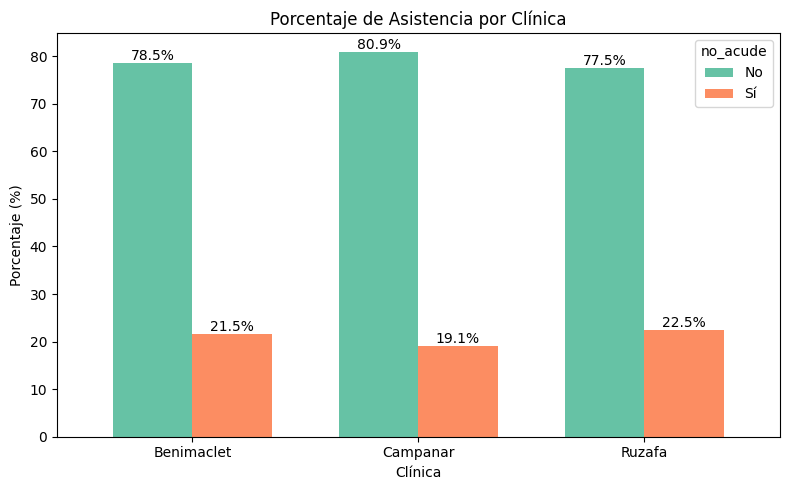

In [61]:
# 1. Calculamos los porcentajes de asistencia por clínica
df_clinica_pct = pd.crosstab(df['clinica'], df['no_acude'], normalize='index') * 100

# 2. Creamos el gráfico de barras
ax = df_clinica_pct.plot(kind='bar', figsize=(8, 5), color=sns.color_palette('Set2'), width=0.7)

plt.title('Porcentaje de Asistencia por Clínica')
plt.ylabel('Porcentaje (%)')
plt.xlabel('Clínica')
plt.xticks(rotation=0) # Mantiene los nombres de las clínicas en horizontal
plt.legend(title='no_acude')

# 3. Añadimos el texto con el % exacto encima de cada barra
for p in ax.patches:
    ax.annotate(f'{p.get_height():.1f}%', 
                (p.get_x() + p.get_width() / 2., p.get_height()), 
                ha='center', va='bottom')

plt.tight_layout()
plt.show()

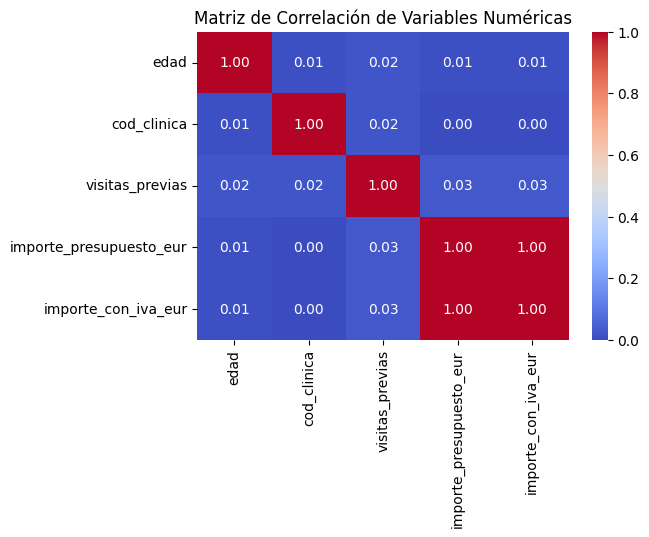

In [ ]:
plt.figure(figsize=(6, 4))
# Calculamos la correlación solo de las numéricas para evitar errores
correlaciones = df.select_dtypes(include=['int64', 'float64']).corr()

sns.heatmap(correlaciones, annot=True, cmap='coolwarm', fmt=".2f", vmin=0, vmax=1)
plt.title('Matriz de Correlación de Variables Numéricas')
plt.show()